In [4]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [5]:
# Load the CSV file into a DataFrame
df_age_height = pd.read_csv('age-height.csv')

# Display the first few rows of the DataFrame
df_age_height.head()

,Age,Gender,Height
0,0.000000,M,54
1,0.000000,F,45
2,0.083333,M,55
3,0.083333,F,53
4,0.166667,M,57


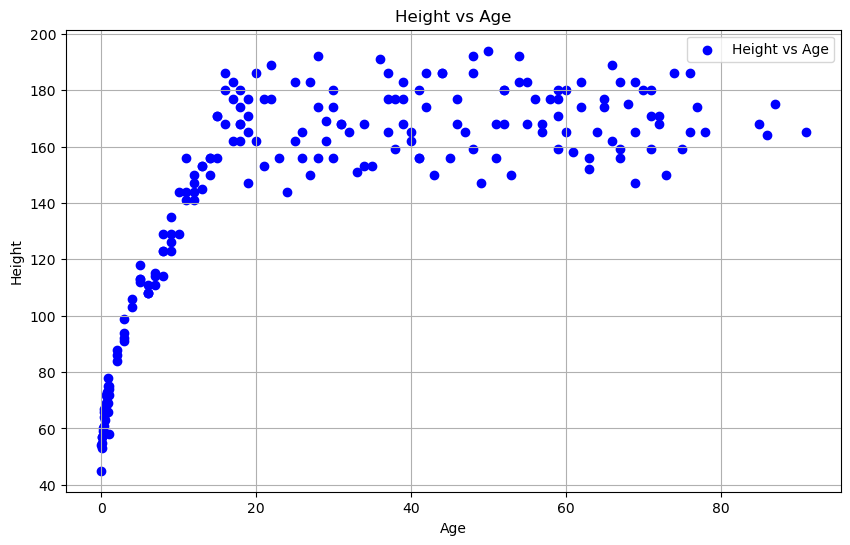

In [22]:
# Plot Height vs Age
plt.figure(figsize=(10, 6))
plt.scatter(df_age_height['Age'], df_age_height['Height'], c='blue', label='Height vs Age')
plt.title('Height vs Age')
plt.xlabel('Age')
plt.ylabel('Height')
plt.legend()
plt.grid(True)
plt.show()

# Feature transformation: Age -> sqrt (Age)
We can transform features to make relationships easier to model. We can linearize a nonlinear relationship via transformation.

In [7]:
# Add a new column 'Age_Squared' by squaring the 'Age' column
df_age_height['Square_Root_of_Age'] = df_age_height['Age'] ** 0.5

# Display the first few rows of the updated DataFrame
df_age_height.head()

,Age,Gender,Height,Square_Root_of_Age
0,0.000000,M,54,0.000000
1,0.000000,F,45,0.000000
2,0.083333,M,55,0.288675
3,0.083333,F,53,0.288675
4,0.166667,M,57,0.408248


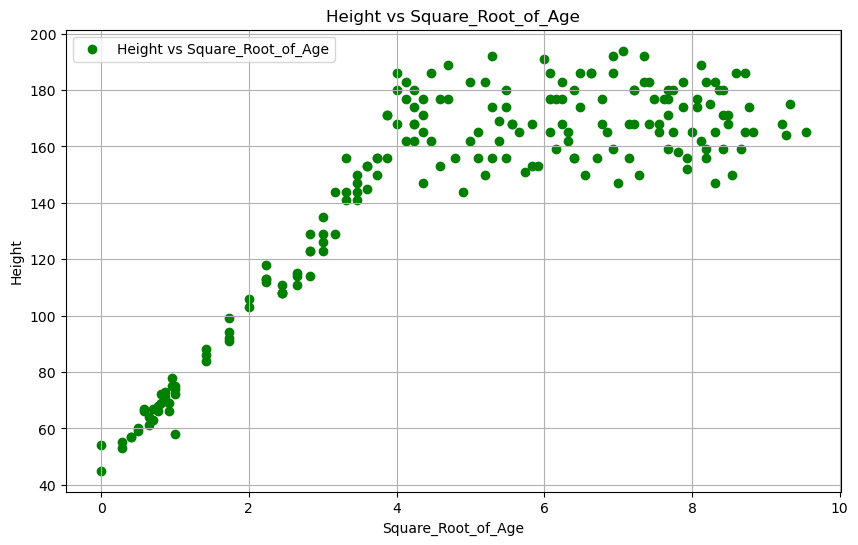

In [8]:
# Plot Age_Squared vs Height
plt.figure(figsize=(10, 6))
plt.scatter(df_age_height['Square_Root_of_Age'], df_age_height['Height'], c='green', label='Height vs Square_Root_of_Age')
plt.title('Height vs Square_Root_of_Age')
plt.xlabel('Square_Root_of_Age')
plt.ylabel('Height')
plt.legend()
plt.grid(True)
plt.show()

Compare a linear regression model fitted on the age vs. a linear regression model fitted on the square root of age.


In [9]:


from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

# Prepare the data
X_original = df_age_height[['Age']].values
X_transformed = df_age_height[['Square_Root_of_Age']].values
y = df_age_height['Height'].values

# Fit the linear regression model on the original data
model_original = LinearRegression()
model_original.fit(X_original, y)
y_pred_original = model_original.predict(X_original)

# Fit the linear regression model on the transformed data
model_transformed = LinearRegression()
model_transformed.fit(X_transformed, y)
y_pred_transformed = model_transformed.predict(X_transformed)

# Calculate the Mean Squared Error for both models
mse_original = mean_squared_error(y, y_pred_original)
mse_transformed = mean_squared_error(y, y_pred_transformed)

print(f'MSE for the original data: {mse_original}')
print(f'MSE for the transformed data: {mse_transformed}')

MSE for the original data: 835.0416876828006
MSE for the transformed data: 487.9866323962737


Let's see why the polynomial regression fitts better: One can see on the plot that a straigth line ca indeed fit the green dots better compared to the bloe dots.

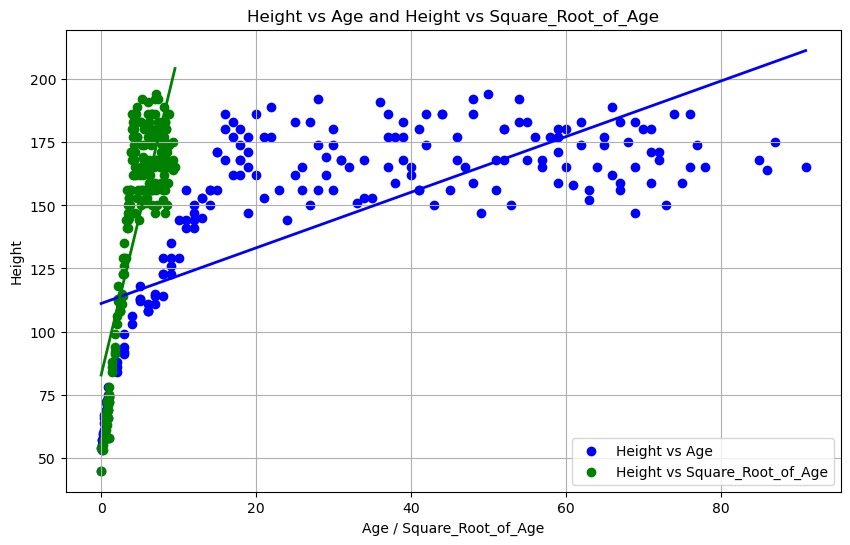

In [10]:
plt.figure(figsize=(10, 6))

# Plot Age vs Height
plt.scatter(df_age_height['Age'], df_age_height['Height'], c='blue', label='Height vs Age')

# Plot Square_Root_of_Age vs Height
plt.scatter(df_age_height['Square_Root_of_Age'], df_age_height['Height'], c='green', label='Height vs Square_Root_of_Age')

plt.title('Height vs Age and Height vs Square_Root_of_Age')
plt.xlabel('Age / Square_Root_of_Age')
plt.ylabel('Height')
plt.legend()
# Plot the regression line for Age vs Height
age_range = np.linspace(0, df_age_height['Age'].max(), 100)
height_pred_age = model_original.predict(age_range.reshape(-1, 1))
plt.plot(age_range, height_pred_age, color='blue', linewidth=2, label='Regression Line (Age)')

# Plot the regression line for Square_Root_of_Age vs Height
sqrt_age_range = np.linspace(0, df_age_height['Square_Root_of_Age'].max(), 100)
height_pred_sqrt_age = model_transformed.predict(sqrt_age_range.reshape(-1, 1))
plt.plot(sqrt_age_range, height_pred_sqrt_age, color='green', linewidth=2, label='Regression Line (Square_Root_of_Age)')

plt.grid(True)
plt.show()

Let's add the gender feature.

In [11]:
# One-hot encode the 'Gender' column 
gender_encoded = pd.get_dummies(df_age_height['Gender'], drop_first=True)

# Prepare the data
X = pd.concat([df_age_height[['Age']], gender_encoded], axis=1)
X_transformed = X.values

# Fit the linear regression model
model_with_gender = LinearRegression()
model_with_gender.fit(X_transformed, y)

# Predict using the model
y_pred_with_gender = model_with_gender.predict(X_transformed)

# Calculate the Mean Squared Error
mse_with_gender = mean_squared_error(y, y_pred_with_gender)

print(f'MSE for the model with Age and Gender: {mse_with_gender}')

MSE for the model with Age and Gender: 814.5562542259016


Let's use all three features: Age, Gender, and Square Root of Age.

In [12]:
# Prepare the data
X_all = pd.concat([df_age_height[['Age', 'Square_Root_of_Age']], gender_encoded], axis=1)
X_all_transformed = X_all.values

# Fit the linear regression model
model_all = LinearRegression()
model_all.fit(X_all_transformed, y)

# Predict using the model
y_pred_all = model_all.predict(X_all_transformed)

# Calculate the Mean Squared Error
mse_all = mean_squared_error(y, y_pred_all)

print(f'MSE for the model with Age, Gender, and Square Root of Age: {mse_all}')

# Print the coefficients of the model
print("Coefficients of the model with Age, Gender, and Square Root of Age:", model_all.coef_)

MSE for the model with Age, Gender, and Square Root of Age: 117.69985813608348
Coefficients of the model with Age, Gender, and Square Root of Age: [-2.99455165 40.55824284  8.98546886]


# Polynomial Logistic Regression

We first generate very non-linearly separable data: A unit circle, inside is one class and outside the other class.

In [13]:
import numpy as np
import pandas as pd

# Number of data points
num_points = 100

# Generate random points
np.random.seed(0)  # For reproducibility
points = np.random.uniform(-2, 2, (num_points, 2))

# Determine if points are inside the unit circle
labels = np.array([1 if x1**2 + x2**2 <= 1 else 0 for x1, x2 in points])

# Create a DataFrame
df_points = pd.DataFrame(points, columns=['x1', 'x2'])
df_points['label'] = labels

# Display the first few rows of the DataFrame
print(df_points.head())

         x1        x2  label
0  0.195254  0.860757      1
1  0.411054  0.179533      1
2 -0.305381  0.583576      1
3 -0.249651  1.567092      0
4  1.854651 -0.466234      0


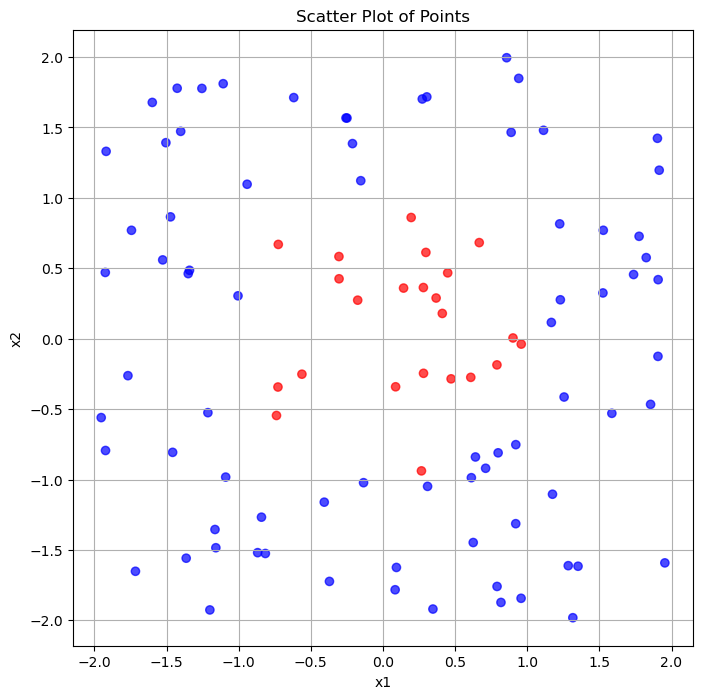

In [14]:
# Plot the points
plt.figure(figsize=(8, 8))
plt.scatter(df_points['x1'], df_points['x2'], c=df_points['label'], cmap='bwr', alpha=0.7)
plt.title('Scatter Plot of Points')
plt.xlabel('x1')
plt.ylabel('x2')
plt.grid(True)
plt.show()

Compare the performance of the Dummy classifier with logistic regression.

In [15]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score

# Prepare the data
X_dummy = df_points[['x1', 'x2']].values
y_dummy = df_points['label'].values

# Create and fit the dummy classifier
dummy_clf = DummyClassifier(strategy="most_frequent")
dummy_clf.fit(X_dummy, y_dummy)

# Predict using the dummy classifier
y_pred_dummy = dummy_clf.predict(X_dummy)

# Calculate the accuracy
accuracy_dummy = accuracy_score(y_dummy, y_pred_dummy)
print(f'Accuracy of the dummy classifier: {accuracy_dummy}')

Accuracy of the dummy classifier: 0.77


In [16]:
from sklearn.linear_model import LogisticRegression

# Prepare the data
X_logistic = df_points[['x1', 'x2']].values
y_logistic = df_points['label'].values

# Fit the logistic regression model
logistic_model = LogisticRegression()
logistic_model.fit(X_logistic, y_logistic)

# Predict using the model
y_pred_logistic = logistic_model.predict(X_logistic)

# Print the accuracy of the model
accuracy = logistic_model.score(X_logistic, y_logistic)
print(f'Accuracy of the logistic regression model: {accuracy}')

Accuracy of the logistic regression model: 0.77


### Some feature ingeneering
We add the square of the features.

In [17]:
# Add new columns for the squared values of x1 and x2
df_points['x1_squared'] = df_points['x1'] ** 2
df_points['x2_squared'] = df_points['x2'] ** 2

# Display the first few rows of the updated DataFrame
print(df_points.head())

         x1        x2  label  x1_squared  x2_squared
0  0.195254  0.860757      1    0.038124    0.740903
1  0.411054  0.179533      1    0.168965    0.032232
2 -0.305381  0.583576      1    0.093257    0.340561
3 -0.249651  1.567092      0    0.062326    2.455777
4  1.854651 -0.466234      0    3.439730    0.217374


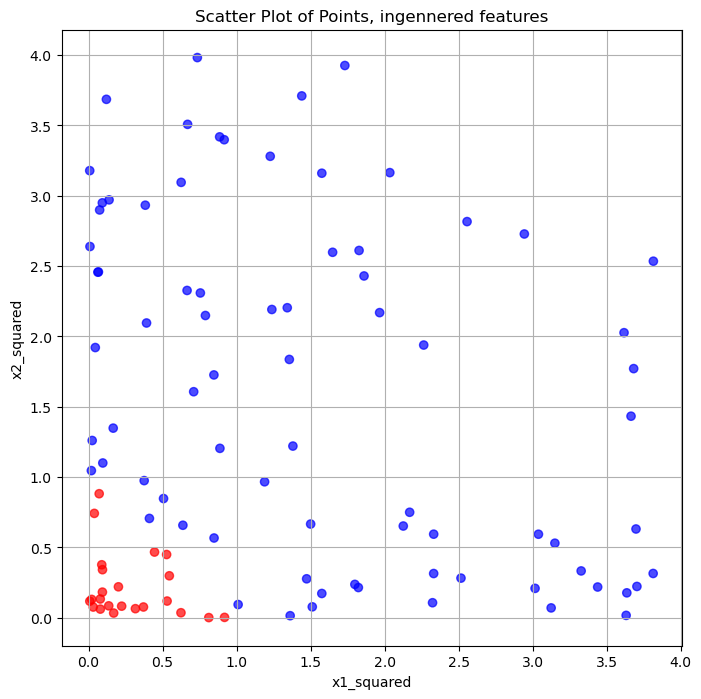

In [18]:
# Plot the points
plt.figure(figsize=(8, 8))
plt.scatter(df_points['x1_squared'], df_points['x2_squared'], c=df_points['label'], cmap='bwr', alpha=0.7)
plt.title('Scatter Plot of Points, ingennered features')
plt.xlabel('x1_squared')
plt.ylabel('x2_squared')
plt.grid(True)
plt.show()

In [19]:
# Prepare the data
X_new_logistic = df_points[['x1_squared', 'x2_squared']].values
y_new_logistic = df_points['label'].values

# Fit the logistic regression model
logistic_model_new = LogisticRegression()
logistic_model_new.fit(X_new_logistic, y_new_logistic)

# Predict using the model
y_pred_new_logistic = logistic_model_new.predict(X_new_logistic)

# Print the accuracy of the model
accuracy_new = logistic_model_new.score(X_new_logistic, y_new_logistic)
print(f'Accuracy of the new logistic regression model: {accuracy_new}')

# Print the coefficients of the model
print("Coefficients of the new logistic regression model:", logistic_model_new.coef_)

Accuracy of the new logistic regression model: 1.0
Coefficients of the new logistic regression model: [[-2.21419394 -2.46072927]]


Let's plot the decision boundary.

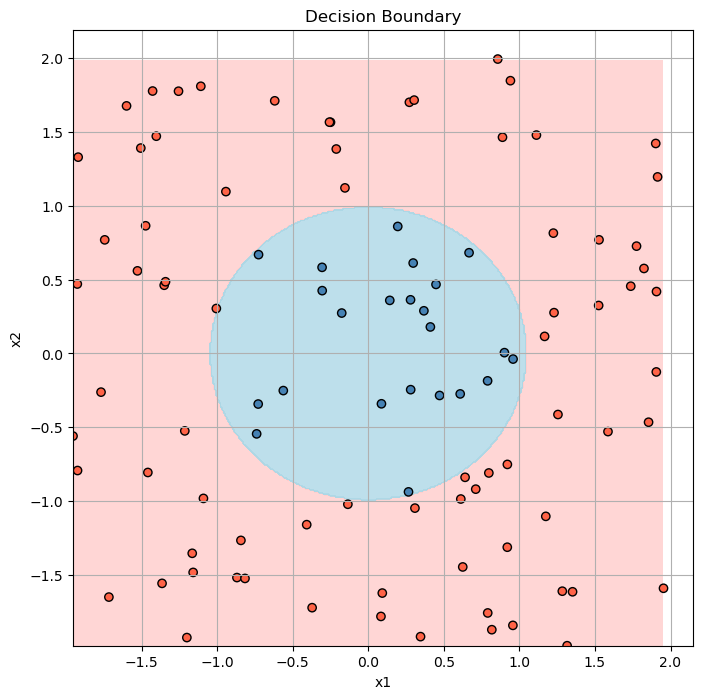

In [20]:
from matplotlib.colors import ListedColormap

# Define a custom color map

# Create a custom pastel color map
cmap_light = ListedColormap(['#FFCCCB', '#ADD8E6'])  # Light red and light blue
cmap_bold = ['#FF6347', '#4682B4']  # Bold colors for the data points

# Create a mesh grid for plotting
x1_min, x1_max = df_points['x1'].min(), df_points['x1'].max()
x2_min, x2_max = df_points['x2'].min(), df_points['x2'].max()
xx1, xx2 = np.meshgrid(np.arange(x1_min, x1_max, 0.01),
                       np.arange(x2_min, x2_max, 0.01))   # Mesh grid points (x1, x2)

# Predict the label for each point in the mesh grid
xx1_squared = xx1.ravel() ** 2
xx2_squared = xx2.ravel() ** 2
Z = logistic_model_new.predict(np.c_[xx1_squared, xx2_squared])
Z = Z.reshape(xx1.shape)

# Make the figure square
plt.figure(figsize=(8, 8))

# Plot the decision boundary using the pastel color map
plt.contourf(xx1, xx2, Z, alpha=0.8, cmap=cmap_light)

# Plot the original points using bold colors
plt.scatter(df_points['x1'], df_points['x2'], c=df_points['label'], cmap=ListedColormap(cmap_bold), edgecolor='k')

plt.title('Decision Boundary')
plt.xlabel('x1')
plt.ylabel('x2')
plt.grid(True)
plt.show()
